<a href="https://colab.research.google.com/github/Martin2513/fives-segmentation-unet-poc/blob/main/unet_poc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import zipfile
from google.colab import drive
from tqdm.auto import tqdm

import random
import numpy as np
import torch
import cv2
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

import torch.nn as nn
import torch.nn.functional as F

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
drive.mount("/content/drive")

ZIP_PATH = "/content/drive/MyDrive/FIVES.zip"
DATA_DIR = "data"

if not os.path.exists(DATA_DIR):
  with zipfile.ZipFile(ZIP_PATH, "r") as z:
    for file in tqdm(z.infolist(), desc="Extracting FIVES"):
      z.extract(file, DATA_DIR)

  print("Extracted to directory:", DATA_DIR)

Mounted at /content/drive


Extracting FIVES:   0%|          | 0/1608 [00:00<?, ?it/s]

Extracted to directory: data


In [3]:
IMG_SIZE = 768
RESIZED_DIR = "data_768"

# Find the root folder in "data"
#(where train/Original and test/Original are)
DATA_ROOT = None
for root, dirs, files in os.walk(DATA_DIR):
    if os.path.isdir(os.path.join(root, "train", "Original")) and os.path.isdir(os.path.join(root, "test", "Original")):
        DATA_ROOT = root
        break

assert DATA_ROOT is not None, "Couldn't find the folders train/Original and test/Original"
print("Dataset found in:", DATA_ROOT)

# Resize and save one split ("train" or "test")
def resize_and_save(split_name):
    src_img_dir = os.path.join(DATA_ROOT, split_name, "Original")
    src_msk_dir = os.path.join(DATA_ROOT, split_name, "Ground truth")
    dst_img_dir = os.path.join(RESIZED_DIR, split_name, "Original")
    dst_msk_dir = os.path.join(RESIZED_DIR, split_name, "Ground truth")

    os.makedirs(dst_img_dir, exist_ok=True)
    os.makedirs(dst_msk_dir, exist_ok=True)

    files = sorted([f for f in os.listdir(src_img_dir) if f.lower().endswith(".png")])
    for fname in tqdm(files, desc=f"Processing {split_name}"):
        dst_img = os.path.join(dst_img_dir, fname)
        dst_msk = os.path.join(dst_msk_dir, fname)
        if os.path.exists(dst_img) and os.path.exists(dst_msk):
            continue

        img = cv2.imread(os.path.join(src_img_dir, fname), cv2.IMREAD_COLOR)
        msk = cv2.imread(os.path.join(src_msk_dir, fname), cv2.IMREAD_GRAYSCALE)

        img_resized = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        msk_resized = cv2.resize(msk, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
        msk_resized = ((msk_resized > 127).astype("uint8")) * 255

        cv2.imwrite(dst_img, img_resized)
        cv2.imwrite(dst_msk, msk_resized)

    return len(files)


n_train = resize_and_save("train")
n_test = resize_and_save("test")
print(f"Saved {n_train} train and {n_test} test images in '{RESIZED_DIR}'.")

Dataset found in: data


Processing train:   0%|          | 0/600 [00:00<?, ?it/s]

Processing test:   0%|          | 0/200 [00:00<?, ?it/s]

Saved 600 train and 200 test images in 'data_768'.


In [4]:
# Set random seed for reproducibility
SEED = 881

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Helper function to extract clinical category from filename
def get_clinical_category(filename):
    base_name = os.path.splitext(filename)[0]
    clinical_category = base_name.split("_")[-1]
    return clinical_category

class FivesDataset(Dataset):
    def __init__(self, img_dir, msk_dir, filenames, augment=False):
        self.img_dir = img_dir
        self.msk_dir = msk_dir
        self.filenames = filenames
        self.augment = augment

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, index):
        fname = self.filenames[index]
        img = cv2.imread(os.path.join(self.img_dir, fname), cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        msk = cv2.imread(os.path.join(self.msk_dir, fname), cv2.IMREAD_GRAYSCALE)

        # Apply identical spatial augmentations to both image and mask
        if self.augment:
            if random.random() < 0.5:
                img = np.fliplr(img).copy()
                msk = np.fliplr(msk).copy()
            if random.random() < 0.5:
                img = np.flipud(img).copy()
                msk = np.flipud(msk).copy()
            k = random.randint(0, 3)
            if k > 0:
                img = np.rot90(img, k).copy()
                msk = np.rot90(msk, k).copy()

        # Normalize image to [0, 1] and convert to PyTorch tensor (C, H, W)
        img_tensor = torch.from_numpy(img).permute(2, 0, 1).float() / 255.0
        msk_tensor = torch.from_numpy((msk > 127).astype(np.float32)).unsqueeze(0)

        return img_tensor, msk_tensor, fname


# Stratified 90/10 split of the 600 training images into train (540) and validation (60)
train_img_dir = os.path.join(RESIZED_DIR, "train", "Original")
train_msk_dir = os.path.join(RESIZED_DIR, "train", "Ground truth")
all_train_files = sorted(os.listdir(train_img_dir))
categories = [get_clinical_category(f) for f in all_train_files]

train_files, validation_files = train_test_split(all_train_files, test_size=0.1, random_state=SEED, stratify=categories)

test_img_dir = os.path.join(RESIZED_DIR, "test", "Original")
test_msk_dir = os.path.join(RESIZED_DIR, "test", "Ground truth")
test_files = sorted(os.listdir(test_img_dir))

BATCH_SIZE = 4
train_ds = FivesDataset(train_img_dir, train_msk_dir, train_files, augment=True)
validation_ds = FivesDataset(train_img_dir, train_msk_dir, validation_files, augment=False)
test_ds = FivesDataset(test_img_dir, test_msk_dir, test_files, augment=False)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)
validation_loader = DataLoader(validation_ds, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)

print(f"Train: {len(train_ds)} | Validation: {len(validation_ds)} | Test: {len(test_ds)}")

Train: 540 | Validation: 60 | Test: 200


In [5]:
class DoubleConv(nn.Module):
    # Two consecutive 3x3 convolutions with BatchNorm and ReLU
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, base_ch=32):
        super().__init__()
        # Encoder (downsampling path)
        self.enc1 = DoubleConv(in_channels, base_ch)
        self.enc2 = DoubleConv(base_ch, base_ch * 2)
        self.enc3 = DoubleConv(base_ch * 2, base_ch * 4)
        self.enc4 = DoubleConv(base_ch * 4, base_ch * 8)
        self.bottleneck = DoubleConv(base_ch * 8, base_ch * 16)
        self.pool = nn.MaxPool2d(2)
        # Decoder (upsampling path with skip connections)
        self.dec4 = DoubleConv(base_ch * 16 + base_ch * 8, base_ch * 8)
        self.dec3 = DoubleConv(base_ch * 8 + base_ch * 4, base_ch * 4)
        self.dec2 = DoubleConv(base_ch * 4 + base_ch * 2, base_ch * 2)
        self.dec1 = DoubleConv(base_ch * 2 + base_ch, base_ch)
        # Final 1x1 convolution producing pixel-wise vessel logits
        self.head = nn.Conv2d(base_ch, out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = F.interpolate(b, size=e4.shape[2:], mode="bilinear", align_corners=False)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))
        d3 = F.interpolate(d4, size=e3.shape[2:], mode="bilinear", align_corners=False)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = F.interpolate(d3, size=e2.shape[2:], mode="bilinear", align_corners=False)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = F.interpolate(d2, size=e1.shape[2:], mode="bilinear", align_corners=False)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.head(d1)


DICE_SMOOTH = 1e-5
# Shared Dice formula
def dice_coefficient(preds, targets, smooth=DICE_SMOOTH):
    preds = preds.float()
    targets = targets.float()
    inter = (preds * targets).sum(dim=(2, 3))
    union = preds.sum(dim=(2, 3)) + targets.sum(dim=(2, 3))
    return ((2.0 * inter + smooth) / (union + smooth)).mean()

def compute_dice(logits, targets, thresh=0.5):
    preds = (torch.sigmoid(logits) > thresh).float()
    return dice_coefficient(preds, targets).item()

class BCEDiceLoss(nn.Module):
    # Combine pixel-wise Binary Cross-Entropy with soft Dice overlap loss
    def __init__(self, smooth=DICE_SMOOTH):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.smooth = smooth

    def forward(self, logits, targets):
        logits = logits.float()
        targets = targets.float()
        bce_loss = self.bce(logits, targets)
        probs = torch.sigmoid(logits)
        dice = dice_coefficient(probs, targets, smooth=self.smooth)
        return 0.5 * bce_loss + 0.5 * (1.0 - dice)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = UNet(in_channels=3, out_channels=1, base_ch=32).to(device)
criterion = BCEDiceLoss()

print(f"Device: {device} | Parameters: {sum(p.numel() for p in model.parameters()):,}")

Device: cuda | Parameters: 7,849,601


Epoch 01/25:   0%|          | 0/135 [00:00<?, ?it/s]

Epoch 01/25 | Train Loss: 0.4649 | Val Loss: 0.3524 | Val Dice: 0.6295


Epoch 02/25:   0%|          | 0/135 [00:00<?, ?it/s]

Epoch 02/25 | Train Loss: 0.2328 | Val Loss: 0.2496 | Val Dice: 0.6754


Epoch 03/25:   0%|          | 0/135 [00:00<?, ?it/s]

Epoch 03/25 | Train Loss: 0.1674 | Val Loss: 0.1569 | Val Dice: 0.8031


... (40 outputs left out)

Epoch 24/25:   0%|          | 0/135 [00:00<?, ?it/s]

Epoch 24/25 | Train Loss: 0.0907 | Val Loss: 0.0882 | Val Dice: 0.8842


Epoch 25/25:   0%|          | 0/135 [00:00<?, ?it/s]

Epoch 25/25 | Train Loss: 0.0905 | Val Loss: 0.0882 | Val Dice: 0.8842

Best Validation Dice: 0.8913


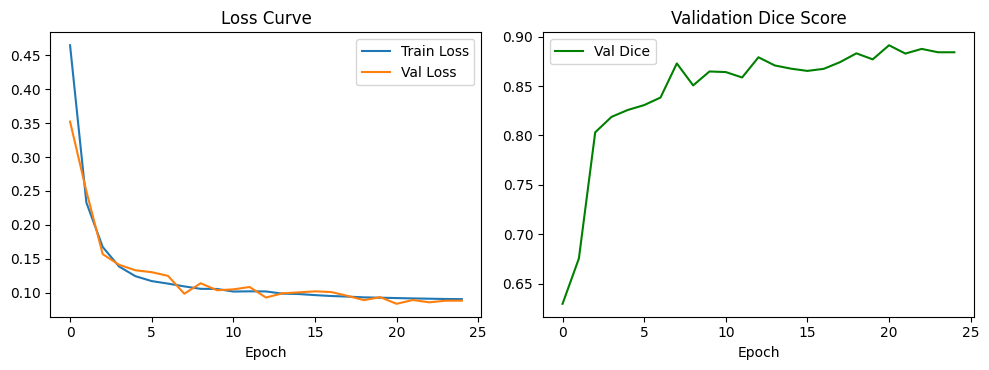

In [6]:
EPOCHS = 25
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

history = {"train_loss": [], "val_loss": [], "val_dice": []}
best_val_dice = 0.0

for epoch in range(1, EPOCHS + 1):
    # Training phase
    model.train()
    train_loss = 0.0
    for imgs, msks, _ in tqdm(train_loader, desc=f"Epoch {epoch:02d}/{EPOCHS}", leave=False):
        imgs = imgs.to(device, non_blocking=True)
        msks = msks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
            logits = model(imgs)
            loss = criterion(logits, msks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        train_loss += loss.item() * imgs.size(0)

    scheduler.step()
    train_loss /= len(train_ds)

    # Validation phase
    model.eval()
    val_loss = 0.0
    val_dice = 0.0
    with torch.no_grad():
        for imgs, msks, _ in validation_loader:
            imgs = imgs.to(device, non_blocking=True)
            msks = msks.to(device, non_blocking=True)
            with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
                logits = model(imgs)
                loss = criterion(logits, msks)
            val_loss += loss.item() * imgs.size(0)
            val_dice += compute_dice(logits, msks) * imgs.size(0)

    val_loss /= len(validation_ds)
    val_dice /= len(validation_ds)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_dice"].append(val_dice)

    # Save best model checkpoint based on validation Dice
    if val_dice > best_val_dice:
        best_val_dice = val_dice
        torch.save(model.state_dict(), "best_unet.pth")

    print(f"Epoch {epoch:02d}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Dice: {val_dice:.4f}")

print(f"\nBest Validation Dice: {best_val_dice:.4f}")

# Plot training and validation curves
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(history["train_loss"], label="Train Loss")
ax[0].plot(history["val_loss"], label="Val Loss")
ax[0].set_title("Loss Curve")
ax[0].set_xlabel("Epoch")
ax[0].legend()

ax[1].plot(history["val_dice"], label="Val Dice", color="green")
ax[1].set_title("Validation Dice Score")
ax[1].set_xlabel("Epoch")
ax[1].legend()

plt.tight_layout()
os.makedirs("results", exist_ok=True)
plt.savefig("results/training_curves.png", dpi=200)
plt.show()

Evaluating test set:   0%|          | 0/50 [00:00<?, ?it/s]



Overall Test Performance


,Dice,IoU,Accuracy,Sensitivity,Specificity
Overall Mean (n=200),0.8697,0.7776,0.9838,0.8606,0.9917
Std,0.0924,0.1021,0.0052,0.1094,0.0037




Performance by Clinical Category


,Dice,IoU,Accuracy,Sensitivity,Specificity
AMD (n=50),0.8922,0.8070,0.9837,0.8943,0.9908
Diabetic Retinopathy (n=50),0.8801,0.7891,0.9853,0.8750,0.9924
Glaucoma (n=50),0.8287,0.7304,0.9861,0.8053,0.9937
Normal (n=50),0.8778,0.7838,0.9800,0.8677,0.9901




Saved test metrics to: results/test_metrics.csv




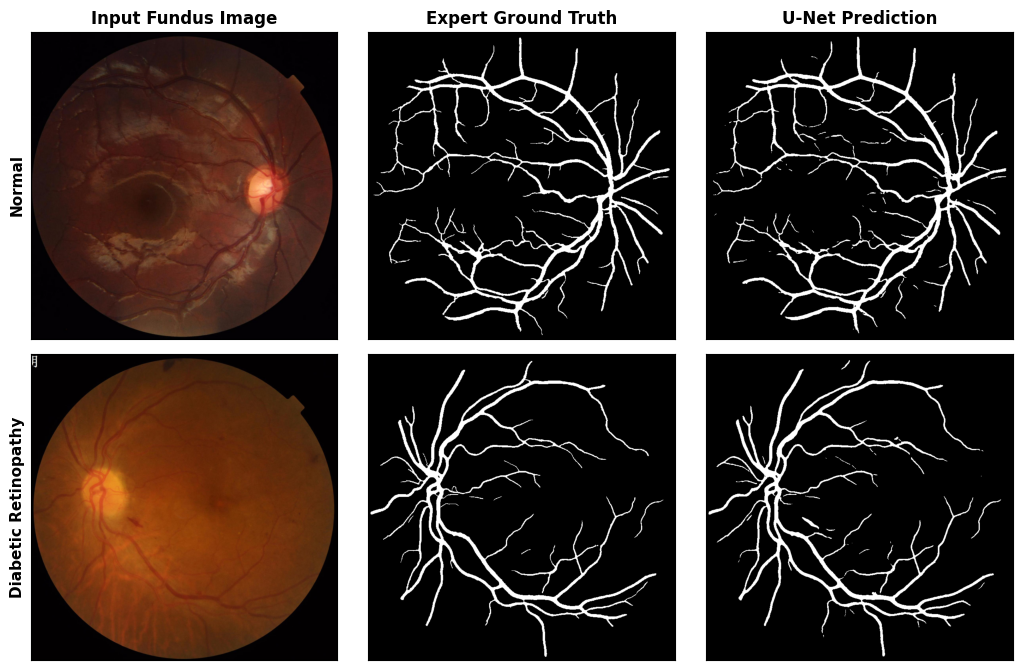

Saved figure (151_N.png, 100_D.png) to: results/fives_unet_comparison.png


In [9]:
# Load best checkpoint weights saved during training
model.load_state_dict(torch.load("best_unet.pth", map_location=device, weights_only=True))
model.eval()

# Evaluate on the official FIVES test set (200 images)
records = []
with torch.no_grad():
    for imgs, msks, fnames in tqdm(test_loader, desc="Evaluating test set"):
        imgs = imgs.to(device)
        with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
            probs = torch.sigmoid(model(imgs)).cpu()
        preds = (probs > 0.5).float()

        for i, fname in enumerate(fnames):
            p = preds[i, 0].numpy()
            g = msks[i, 0].numpy()

            tp = np.logical_and(p == 1, g == 1).sum()
            fp = np.logical_and(p == 1, g == 0).sum()
            fn = np.logical_and(p == 0, g == 1).sum()
            tn = np.logical_and(p == 0, g == 0).sum()

            dice = (2.0 * tp + DICE_SMOOTH) / (2.0 * tp + fp + fn + DICE_SMOOTH)
            iou = (tp + DICE_SMOOTH) / (tp + fp + fn + DICE_SMOOTH)
            acc = (tp + tn) / (tp + tn + fp + fn)
            sens = (tp + DICE_SMOOTH) / (tp + fn + DICE_SMOOTH)
            spec = (tn + DICE_SMOOTH) / (tn + fp + DICE_SMOOTH)

            records.append({
                "file": fname,
                "category": get_clinical_category(fname),
                "Dice": dice,
                "IoU": iou,
                "Accuracy": acc,
                "Sensitivity": sens,
                "Specificity": spec,
            })

df_results = pd.DataFrame(records)
category_names = {"N": "Normal", "D": "Diabetic Retinopathy", "G": "Glaucoma", "A": "AMD"}
df_results["Category"] = df_results["category"].map(category_names)

metrics = ["Dice", "IoU", "Accuracy", "Sensitivity", "Specificity"]
overall = df_results[metrics].agg(["mean", "std"]).round(4)
overall.index = [f"Overall Mean (n={len(df_results)})", "Std"]

by_category = df_results.groupby("Category")[metrics].mean().round(4)
counts = df_results["Category"].value_counts()
by_category.index = [f"{cat} (n={counts[cat]})" for cat in by_category.index]

print("\n")
print("Overall Test Performance")
display(overall)
print("\n")
print("Performance by Clinical Category")
display(by_category)
print("\n")


# Save per-image metrics CSV
METRICS_PATH = "results/test_metrics.csv"
df_results.to_csv(METRICS_PATH, index=False)
print(f"Saved test metrics to: {METRICS_PATH}")
print("\n")


# Save visual comparison figure for the paper
sample_n = next(f for f in test_files if get_clinical_category(f) == "N")
sample_d = next(f for f in test_files if get_clinical_category(f) == "D")
selected = [(sample_n, "Normal"), (sample_d, "Diabetic Retinopathy")]

fig, axes = plt.subplots(len(selected), 3, figsize=(10.5, 6.8))
col_titles = ["Input Fundus Image", "Expert Ground Truth", "U-Net Prediction"]

with torch.no_grad():
    for row, (fname, label) in enumerate(selected):
        img_bgr = cv2.imread(os.path.join(test_img_dir, fname), cv2.IMREAD_COLOR)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        gt = cv2.imread(os.path.join(test_msk_dir, fname), cv2.IMREAD_GRAYSCALE)

        inp = torch.from_numpy(img_rgb).permute(2, 0, 1).float().unsqueeze(0).to(device) / 255.0
        with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
            pred = (torch.sigmoid(model(inp))[0, 0].cpu().numpy() > 0.5).astype(np.uint8) * 255

        axes[row, 0].imshow(img_rgb)
        axes[row, 1].imshow(gt, cmap="gray")
        axes[row, 2].imshow(pred, cmap="gray")
        axes[row, 0].set_ylabel(label, fontsize=11, fontweight="bold")

        for col in range(3):
            axes[row, col].set_xticks([])
            axes[row, col].set_yticks([])
            if row == 0:
                axes[row, col].set_title(col_titles[col], fontsize=12, fontweight="bold")

plt.tight_layout()
FIGURE_PATH = "results/fives_unet_comparison.png"
plt.savefig(FIGURE_PATH, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved figure ({sample_n}, {sample_d}) to: {FIGURE_PATH}")